# Descriptives: simulated demand datasets

Three simulated datasets in `code/build/input/public/simulation/` (10 markets x 3 products, 100 x 3, 100 x 5). Variables: `shares` (J x M), `P_opt` (J x M prices), `x1` (product characteristics, 3 cols), `w` (cost shifter), `Z` (instrument), `xi_all` (demand shock), `eta` (cost shock), `alphas` (M x 500 draws of the price coefficient). Product-level vectors are stacked market by market (assumed), matching `vec(shares)`.

In [1]:
using MAT, DataFrames, Statistics, StatsBase, Plots, Printf
raw = Dict(
    "10markets3products"  => matread("../build/input/public/simulation/10markets3products.mat"),
    "100markets3products" => matread("../build/input/public/simulation/100markets3products.mat"),
    "100markets5products" => matread("../build/input/public/simulation/100markets5products.mat"),
)
Base.active_project()

[ Info: Precompiling IJuliaExt [64482eec-cc57-5312-bea1-9f24eb636db7] 

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up


[ Info: Precompiling IJuliaExt [2f4121a4-3b3a-5ce6-9c5e-1f2673ce168a] 

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up


"/home/repo-intro/scripts/julia/Project.toml"

In [2]:
function product_df(d)
    J, M = size(d["shares"])
    df = DataFrame(market = repeat(1:M, inner = J), product = repeat(1:J, outer = M),
                   share = vec(d["shares"]), price = vec(d["P_opt"]),
                   x1_1 = d["x1"][:, 1], x1_2 = d["x1"][:, 2], x1_3 = d["x1"][:, 3],
                   w = vec(d["w"]), Z = vec(d["Z"]), xi = vec(d["xi_all"]), eta = vec(d["eta"]))
    df.outside = 1 .- combine(groupby(df, :market), :share => sum => :s).s[df.market]
    df
end
data = Dict(k => product_df(v) for (k, v) in raw)
DataFrame(dataset = collect(keys(data)), obs = [nrow(data[k]) for k in keys(data)],
          markets = [length(unique(data[k].market)) for k in keys(data)],
          products = [length(unique(data[k].product)) for k in keys(data)],
          alpha_draws = [size(raw[k]["alphas"], 2) for k in keys(data)])

Row,dataset,obs,markets,products,alpha_draws
,String,Int64,Int64,Int64,Int64
1,100markets5products,500,100,5,500
2,100markets3products,300,100,3,500
3,10markets3products,30,10,3,500


## Summary statistics by dataset

In [3]:
function desc(df)
    vars = [:share, :outside, :price, :x1_1, :x1_2, :x1_3, :w, :Z, :xi, :eta]
    DataFrame(variable = vars,
        mean = [mean(df[!, v]) for v in vars], std = [std(df[!, v]) for v in vars],
        min = [minimum(df[!, v]) for v in vars], p50 = [median(df[!, v]) for v in vars],
        max = [maximum(df[!, v]) for v in vars])
end
for k in sort(collect(keys(data)))
    println("\n== ", k, " (N = ", nrow(data[k]), ") ==")
    show(stdout, desc(data[k]); allrows = true, allcols = true, eltypes = false); println()
end


== 100markets3products (N = 300) ==
10×6 DataFrame
 Row │ variable  mean        std       min          p50          max      
─────┼────────────────────────────────────────────────────────────────────
   1 │ share      0.224478   0.226342   1.0938e-5    0.14197     0.82444
   2 │ outside    0.326565   0.190694   0.00456653   0.299588    0.828688
   3 │ price      3.02655    1.37116    0.163102     2.82786     7.02848
   4 │ x1_1       1.0        0.0        1.0          1.0         1.0
   5 │ x1_2       0.521274   0.284369   0.00170379   0.537318    0.999494
   6 │ x1_3       0.0498103  0.955077  -2.96115     -0.00338337  2.63444
   7 │ w          0.1404     0.812495  -0.753643    -0.0350238   1.20987
   8 │ Z         -0.0420568  0.991763  -2.29662     -0.0667057   2.89625
   9 │ xi         0.043461   1.00373   -2.84349     -0.00765533  3.27085
  10 │ eta       -0.0471291  1.03964   -3.29255      0.00230153  3.41884



== 100markets5products (N = 500) ==
10×6 DataFrame
 Row │ variable  mean        std       min          p50         max      
─────┼───────────────────────────────────────────────────────────────────
   1 │ share      0.190747   0.243292   5.16551e-6   0.0614537  0.893387
   2 │ outside    0.0462645  0.067962   7.71882e-5   0.0187555  0.363287
   3 │ price      1.89109    1.4349    -1.60735      1.81589    7.54714
   4 │ x1_1       1.0        0.0        1.0          1.0        1.0
   5 │ x1_2       0.528951   0.279686   0.00170379   0.541333   0.999494
   6 │ x1_3      -0.0384182  0.986192  -2.96115     -0.0997206  3.27085
   7 │ w         -0.934766   0.830958  -2.07477     -0.728031   0.28472
   8 │ Z          0.0059169  0.948489  -2.54393      0.0219247  2.96214
   9 │ xi         0.0531925  0.988621  -2.90156      0.128751   2.46007
  10 │ eta       -0.0226879  1.02958   -2.89737     -0.0417241  2.79762

== 10markets3products (N = 30) ==
10×6 DataFrame
 Row │ variable  mean       std

## Missing / non-finite values and share checks

In [4]:
DataFrame(dataset = sort(collect(keys(data))),
    nonfinite = [sum(.!isfinite.(Matrix(data[k][:, 3:end]))) for k in sort(collect(keys(data)))],
    min_outside = [minimum(data[k].outside) for k in sort(collect(keys(data)))],
    mean_outside = [mean(data[k].outside) for k in sort(collect(keys(data)))],
    nonpositive_share = [sum(data[k].share .<= 0) for k in sort(collect(keys(data)))])

Row,dataset,nonfinite,min_outside,mean_outside,nonpositive_share
,String,Int64,Float64,Float64,Int64
1,100markets3products,0,0.00456653,0.326565,0
2,100markets5products,0,7.71882e-5,0.0462645,0
3,10markets3products,0,0.000508865,0.237157,0


## Correlations (largest dataset, 100 markets x 5 products)

In [5]:
df = data["100markets5products"]
vars = [:share, :price, :x1_1, :x1_2, :x1_3, :w, :Z, :xi, :eta]
C = cor(Matrix(df[:, vars]))
DataFrame(round.(C, digits = 2), string.(vars)) |> d -> insertcols(d, 1, :var => vars)

Row,var,share,price,x1_1,x1_2,x1_3,w,Z,xi,eta
,Symbol,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,share,1.0,-0.63,NaN,0.1,0.24,-0.45,-0.44,0.18,-0.49
2,price,-0.63,1.0,NaN,-0.04,-0.04,0.45,0.54,0.05,0.65
3,x1_1,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN
4,x1_2,0.1,-0.04,NaN,1.0,0.04,-0.05,-0.02,-0.09,-0.04
5,x1_3,0.24,-0.04,NaN,0.04,1.0,-0.09,-0.02,0.04,-0.05
6,w,-0.45,0.45,NaN,-0.05,-0.09,1.0,-0.07,-0.05,0.02
7,Z,-0.44,0.54,NaN,-0.02,-0.02,-0.07,1.0,-0.01,0.05
8,xi,0.18,0.05,NaN,-0.09,0.04,-0.05,-0.01,1.0,0.04
9,eta,-0.49,0.65,NaN,-0.04,-0.05,0.02,0.05,0.04,1.0


## Consumer price coefficients (`alphas`)

In [6]:
DataFrame(dataset = sort(collect(keys(raw))),
    mean = [mean(raw[k]["alphas"]) for k in sort(collect(keys(raw)))],
    std = [std(raw[k]["alphas"]) for k in sort(collect(keys(raw)))],
    min = [minimum(raw[k]["alphas"]) for k in sort(collect(keys(raw)))],
    max = [maximum(raw[k]["alphas"]) for k in sort(collect(keys(raw)))])

Row,dataset,mean,std,min,max
,String,Float64,Float64,Float64,Float64
1,100markets3products,2.64283,2.10863,1.01129,62.8841
2,100markets5products,2.6433,2.11648,1.01129,62.8841
3,10markets3products,2.65266,2.11277,1.03802,34.215


## Distributions

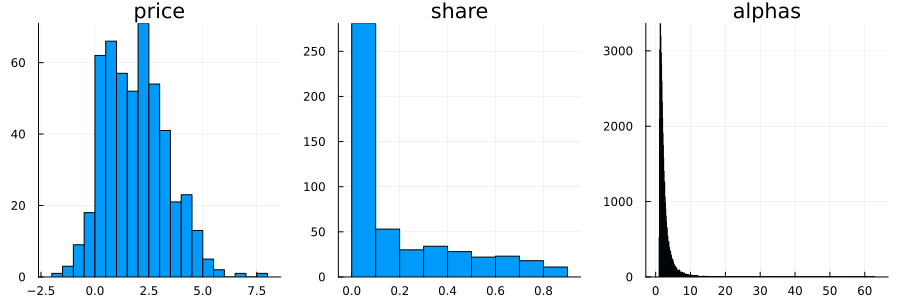

In [7]:
default(size = (900, 300))
ks = sort(collect(keys(data)))
plot(histogram(data[ks[2]].price, title = "price", legend = false),
     histogram(data[ks[2]].share, title = "share", legend = false),
     histogram(vec(raw[ks[2]]["alphas"]), title = "alphas", legend = false), layout = (1, 3))